# Hydraulic analysis of Koto city

In this notebook you will the different parts of the hydraulic analysis of Koto city, district within Tokyo metropolis.
Data used to calculate and determine hydraulic parameters were gatehered from the following sources:
- Precipitation and other atmospheric data courtesy of the Japan Meteorological Agency 
- Water level data: Water Information System courtesy of the Ministry of Land, Infrastructure, Transport and Tourism of Japan (Chart datum: Arakawa Peil [A.P.])
- Tidal data: Tide Table Tokyo courtesy of the Japan Meteorological Agency with an average spring tidal range of 187 cm or 1.87 m

In [47]:
#Packages used in this analysis
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats


In [48]:
# #import of atmospheric data 
# import xarray
# filename = 'https://data.gdex.ucar.edu/d640000/kerchunk/anl_isentrop-remote-https.parq'
# ds = xarray.open_dataset(filename, engine='kerchunk')
# ds['bvf2-theta-an-gauss'] # Square of Brunt-Vaisala frequency

In [49]:
# def parse_jp_datetime(year, dt):
#     if pd.isna(dt):
#         return pd.NaT
#     dt = str(dt).replace("年", "").replace("月", "/").replace("日", "").strip()
#     if dt.endswith(" 24:00"):
#         dt = dt.replace(" 24:00", " 00:00")
#         d = pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")
#         if pd.notna(d):
#             return d + pd.Timedelta(days=1)
#         return d
#     return pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")

In [50]:
# # Read and process hydraulic data for Sumida River (upstream)
# from io import StringIO

# with open("iwabuchi_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_up = "\n".join(valid_lines)

# sumida_up = pd.read_csv(
#     StringIO(data_sumida_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_up = sumida_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_maxWL"])]

# sumida_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_minWL"])]


In [51]:
# # Read and process hydraulic data for Sumida River (downstream)
# from io import StringIO

# with open("reiganjima_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_down = "\n".join(valid_lines)

# sumida_down = pd.read_csv(
#     StringIO(data_sumida_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_down = sumida_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_maxWL"])]

# sumida_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_minWL"])]




In [52]:
# # Read and process hydraulic data for Arakawa River (upstream)
# from io import StringIO

# with open("nanbata_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_up = "\n".join(valid_lines)

# arakawa_up = pd.read_csv(
#     StringIO(data_arakawa_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_up = arakawa_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_maxWL"])]

# arakawa_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_minWL"])]

In [53]:
# # Read and process hydraulic data for Arakawa River (midstream)
# from io import StringIO

# with open("nishiarai_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_mid = "\n".join(valid_lines)

# arakawa_mid = pd.read_csv(
#     StringIO(data_arakawa_mid),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# arakawa_mid = arakawa_mid[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_mid.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_mid["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_maxWL"])]

# arakawa_mid["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_minWL"])]


In [54]:
# # Read and process hydraulic data for Arakawa River (downstream)
# from io import StringIO

# with open("onagigawa_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_down = "\n".join(valid_lines)

# arakawa_down = pd.read_csv(
#     StringIO(data_arakawa_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_down = arakawa_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                         'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_maxWL"])]

# arakawa_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_minWL"])]


In [55]:
# #Saving dataframes to CSV files
# sumida_up.to_csv('sumida_upstream_iwabuchi.csv', index=False)
# sumida_down.to_csv('sumida_downstream_reiganjima.csv', index=False)
# arakawa_up.to_csv('arakawa_upstream_nanbata.csv', index=False)
# arakawa_mid.to_csv('arakawa_midstream_nishiarai.csv', index=False)
# arakawa_down.to_csv('arakawa_downstream_onagigawa.csv', index=False)

In [56]:
#Load csv files into dataframes
sumida_up = pd.read_csv('sumida_upstream_iwabuchi.csv')
sumida_down = pd.read_csv('sumida_downstream_reiganjima.csv')
arakawa_up = pd.read_csv('arakawa_upstream_nanbata.csv')
arakawa_mid = pd.read_csv('arakawa_midstream_nishiarai.csv')
arakawa_down = pd.read_csv('arakawa_downstream_onagigawa.csv')

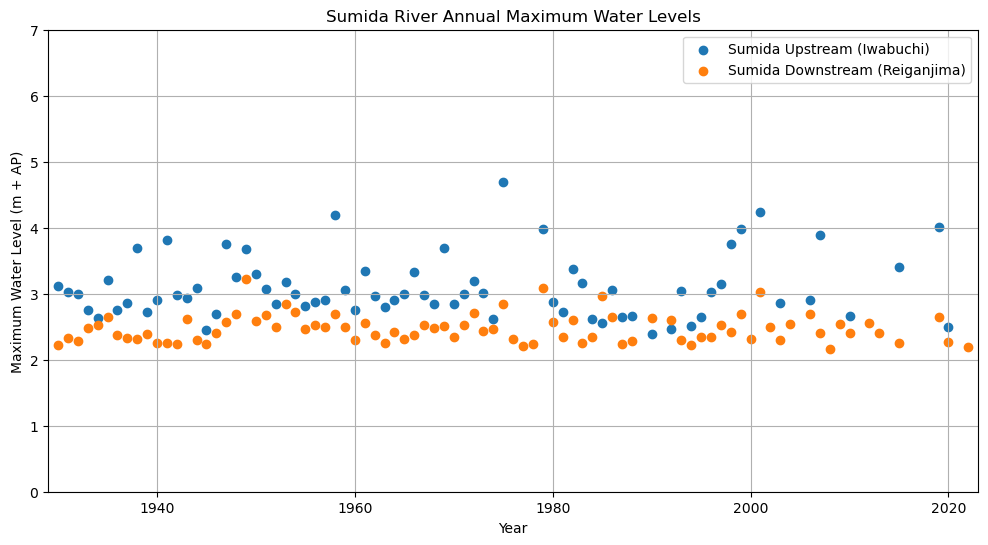

In [57]:
#Sumida river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(sumida_up['year'], sumida_up['maxWL'], label='Sumida Upstream (Iwabuchi)')
plt.scatter(sumida_down['year'], sumida_down['maxWL'], label='Sumida Downstream (Reiganjima)')
plt.title('Sumida River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(sumida_down['year'].min()-1, sumida_up['year'].max()+1)
plt.ylim(0, 7)
plt.grid()
plt.legend()
plt.show()

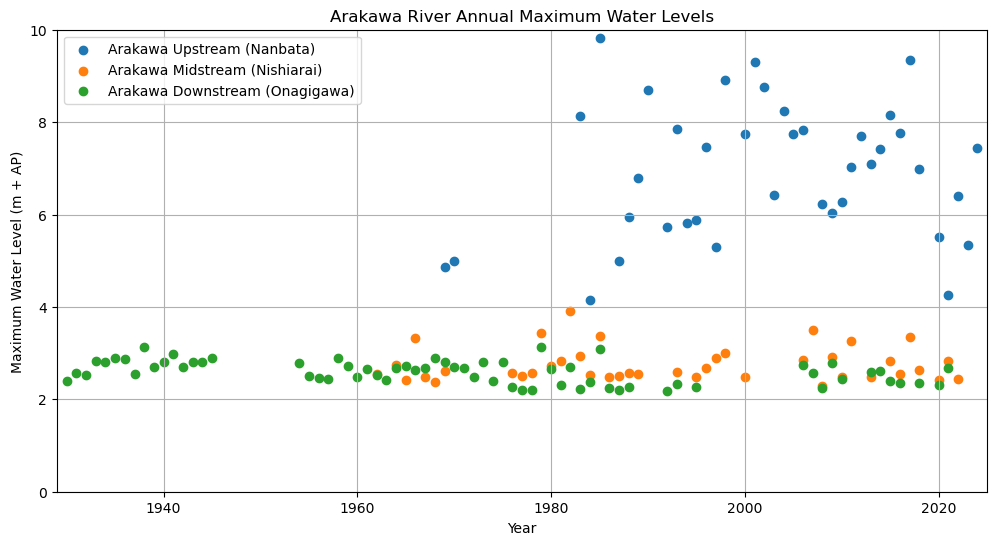

In [58]:
#Arakawa river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(arakawa_up['year'], arakawa_up['maxWL'], label='Arakawa Upstream (Nanbata)')
plt.scatter(arakawa_mid['year'], arakawa_mid['maxWL'], label='Arakawa Midstream (Nishiarai)')
plt.scatter(arakawa_down['year'], arakawa_down['maxWL'], label='Arakawa Downstream (Onagigawa)')
plt.title('Arakawa River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(arakawa_down['year'].min()-1, arakawa_up['year'].max()+1)
plt.ylim(0, 10)
plt.grid()
plt.legend()
plt.show()

In [59]:
# Load precipitation data for analysis
P_tokyo = pd.read_csv('monthly_total_P_tokyo.csv', delimiter=';', encoding='utf-8')

dict_months = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
mean_permonth = np.array([])
for month, name in dict_months.items():
    mean_permonth = np.append(mean_permonth, P_tokyo[name].mean())
total_annual_mean_prcp = P_tokyo['Annual'].mean()

print(mean_permonth)
print(total_annual_mean_prcp)

[ 51.118       67.92066667 109.87266667 131.03466667 144.18266667
 174.7986755  141.60860927 152.42119205 218.92450331 200.30529801
  95.51589404  54.7615894 ]
1539.1258278145694


In [ ]:
#Restructure into new dataframe with three columns: date, precipitation and annual_p
P_monthly = pd.DataFrame({"date": pd.date_range(start='1875-01-01', end='2025-12-31', freq='ME'),
    "precipitation": P_tokyo[["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]].to_numpy().flatten()})

P_monthly = P_monthly.iloc[5:].reset_index(drop=True)  # Reset index after slicing to remove missing values at the beginning of the dataset

# wet_year_total = P_monthly.groupby(P_monthly['date'].dt.year)['precipitation'].sum().reset_index() # from october to september rolling average


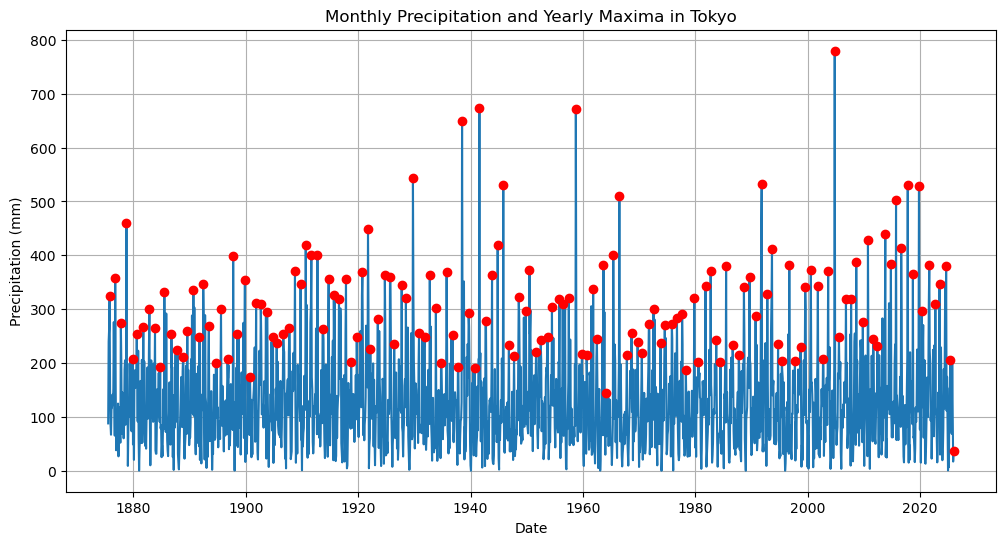

In [81]:
# #Sampling for yearly precipitation maxima
P_monthly['year'] = P_monthly['date'].dt.isocalendar().year
P_monthly_idxmax = P_monthly.groupby('year')['precipitation'].idxmax()
P_monthly_yearly_max = P_monthly.loc[P_monthly_idxmax].reset_index(drop=True)


plt.figure(figsize=(12, 6))
plt.plot(P_monthly['date'], P_monthly['precipitation'], label='Monthly Precipitation')
plt.plot(P_monthly_yearly_max['date'], P_monthly_yearly_max['precipitation'], 'ro', label='Yearly Maxima')
plt.title('Monthly Precipitation and Yearly Maxima in Tokyo')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.grid()
plt.show()
